# 삼성전자 주가 트렌드 분석 노트북 (2023.1 ~ 2026.10)

이 노트북은 [REPORT.md](REPORT.md)의 분석을 처음부터 순서대로 다시 실행한다. 계산 함수는 `src/` 폴더에 있고, 노트북과 `python -m src.run_all` 스크립트가 같은 함수를 쓴다.

| 단계 | 내용 |
|---|---|
| 1 | 데이터 불러오기와 기본 정보 (기간, 컬럼, 결측치) |
| 2 | 결측치·이상치 점검과 처리 기준 |
| 3 | 시계열 지표 계산 (이동평균, 수익률, 변동성, 낙폭, 상관) |
| 4 | 질문 5개에 대한 시각화와 관찰·해석 |
| 5 | 보너스: STL 분해, 베이스라인 예측 |

**실행 방법:** 저장소 루트에서 `jupyter notebook analysis.ipynb`를 열고 위에서부터 차례로 실행한다(약 20초). 그림은 `images/` 폴더에 다시 저장된다.

**분석 질문**
1. Q1 추세: 삼성전자 주가는 어떤 국면을 거쳤고 추세는 언제 바뀌었나?
2. Q2 상대 성과: SK하이닉스·KOSPI와 비교하면 어땠나?
3. Q3 변동성: 변동성은 언제 커졌고, 급변일은 시장 전체 충격과 겹치나?
4. Q4 동조화: 시장·SK하이닉스와 함께 움직인 정도는 어떻게 변했나?
5. Q5 계절성: 특정 달·요일의 반복 패턴이 있나?

## 0. 준비

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from src import config as C, prepare, quality, metrics as M, advanced as A, plots as P
from src.run_all import compute_results

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
font = P.setup_style()
print("그래프 한글 글꼴:", font)

그래프 한글 글꼴: Noto Sans CJK KR


## 1. 데이터 불러오기와 기본 정보

In [2]:
stocks, kospi = prepare.load_raw()
print("종목 원자료:", stocks.shape, "| KOSPI 집계:", kospi.shape)
print("수집 기간:", stocks["Date"].min().date(), "~", stocks["Date"].max().date())
print("종목별 행 수:", stocks.groupby("Name").size().to_dict())
stocks.head(4)

종목 원자료: (2104, 13) | KOSPI 집계: (1052, 6)
수집 기간: 2022-07-01 ~ 2026-10-22
종목별 행 수: {'SK하이닉스': 1052, '삼성전자': 1052}


,Date,Code,Name,Open,High,Low,Close,Volume,Amount,Changes,ChangesRatio,Marcap,Stocks
0,2022-07-01,000660,SK하이닉스,91000,92500,87100,87500,4959176,440689971812,-3500,-3.85,63700206937500,728002365
1,2022-07-01,005930,삼성전자,56900,57500,55900,56200,24982097,1412473217495,-800,-1.40,335501779310000,5969782550
2,2022-07-04,000660,SK하이닉스,87500,89600,86300,89100,4331728,382388292200,1600,1.83,64865010721500,728002365
3,2022-07-04,005930,삼성전자,56100,57400,55700,57100,17807126,1012586831300,900,1.60,340874583605000,5969782550


In [3]:
print("컬럼과 자료형")
stocks.dtypes.to_frame("dtype").T

컬럼과 자료형


,Date,Code,Name,Open,High,Low,Close,Volume,Amount,Changes,ChangesRatio,Marcap,Stocks
dtype,datetime64[us],str,str,int64,int64,int64,int64,int64,int64,int64,float64,int64,int64


In [4]:
kospi.tail(3)

,Date,n_constituents,ret_kospi_pct,ret_ex2_pct,mcap_kospi_total,mcap_kospi_common
1049,2026-10-20,829,-3.732670,-3.939662,4583867698932456,4426658058670174
1050,2026-10-21,829,3.293468,1.035174,4734420227927205,4572147596361253
1051,2026-10-22,829,-3.520190,-2.430601,4569053006370941,4411396975825738


- 원천은 한국거래소(KRX) 전종목 일별 시세이고, 공개 저장소 FinanceData/marcap의 커밋 `eeed081`로 고정했다.
- 분석 기간은 **2023-01-02 ~ 2026-10-22, 927거래일**이다. 그 앞 125거래일(2022-07-01 ~ 2022-12-29)은 120일 이동평균 계산용 준비 구간이다.
- KOSPI는 같은 원천에서 'KOSPI 보통주의 전일 시가총액 가중 등락률'로 직접 계산했다. 보도된 공식 종가 14개 시점과 비교한 차이는 최대 0.17%다.

## 2. 결측치·이상치 점검

| 점검 | 기준 | 처리 |
|---|---|---|
| 결측치 | 빈 값 개수 | 0이어야 한다 |
| 거래일 누락 | 공휴일 달력·KRX 규정으로 데이터와 따로 만든 휴장일 목록과 두 방향 대조 | 휴장일이면 결측이 아니므로 채우지 않는다 |
| 오류형 이상치 | 가격 논리, 가격제한폭 ±30%, 전일대비 일관성 | 발견되면 제외 대상 |
| 통계적 극단값 | \|z\| > 3 | 실제 사건이므로 지우지 않고 '급변일'로 표시 |
| 교차 출처 대조 | 언론 보도 수치와 비교 | 데이터 신뢰도 확인 |

In [5]:
daily = prepare.build_daily(stocks, kospi)
q, cp = quality.run_quality_checks(stocks, kospi, daily)
summary = pd.DataFrame([
    ("결측치(종목 원자료)", sum(q["missing"]["stocks"].values())),
    ("결측치(KOSPI 집계)", sum(q["missing"]["kospi"].values())),
    ("(날짜, 종목) 중복", q["duplicates"]),
    ("데이터에 없는 평일", q["closures"]["weekday_non_trading_days"]),
    ("그중 휴장일로 설명되지 않는 날", len(q["closures"]["unexplained"])),
    ("휴장일인데 거래된 날 (반대 방향 대조)", len(q["closures"]["reference_days_that_traded"])),
    ("가격 논리 위반", q["error_outliers"]["ohlc_logic_violations"]),
    ("가격제한폭(±30%) 초과", q["error_outliers"]["price_limit_violations"]),
    ("전일대비 불일치", q["error_outliers"]["changes_mismatch"]),
    ("등락률 불일치", q["error_outliers"]["ratio_mismatch"]),
    ("교차 대조 통과 / 전체", f"{q['checkpoints']['passed']} / {q['checkpoints']['n']}"),
], columns=["점검", "결과"])
print("모든 필수 점검 통과:", q["all_hard_checks_passed"])
summary

모든 필수 점검 통과: True


,점검,결과
0,결측치(종목 원자료),0
1,결측치(KOSPI 집계),0
2,"(날짜, 종목) 중복",0
3,데이터에 없는 평일,67
4,그중 휴장일로 설명되지 않는 날,0
5,휴장일인데 거래된 날 (반대 방향 대조),0
6,가격 논리 위반,0
7,가격제한폭(±30%) 초과,0
8,전일대비 불일치,0
9,등락률 불일치,0


In [6]:
closures = pd.read_csv(C.CLOSURES_CSV)
print("휴장 사유 예시")
closures.head(8)

휴장 사유 예시


,date,weekday,reason,basis
0,2023-01-23,월,설날 다음날,holidays.KR
1,2023-01-24,화,설날 대체 휴일,holidays.KR
2,2023-03-01,수,삼일절,holidays.KR
3,2023-05-01,월,근로자의 날 (KRX 휴장),KRX 규정
4,2023-05-05,금,어린이날,holidays.KR
5,2023-05-29,월,부처님오신날 대체 휴일,holidays.KR
6,2023-06-06,화,현충일,holidays.KR
7,2023-08-15,화,광복절,holidays.KR


In [7]:
ext = pd.DataFrame({k: v["by_year"] for k, v in q["statistical_extremes"].items()}).rename(
    columns={"sec": "삼성전자", "skh": "SK하이닉스", "kospi": "KOSPI"})
ext.loc["합계"] = ext.sum()
print("연도별 급변일(|z| > 3) 개수")
ext

연도별 급변일(|z| > 3) 개수


,삼성전자,SK하이닉스,KOSPI
2023,0,0,0
2024,1,0,1
2025,0,0,1
2026,19,13,19
합계,20,13,21


In [8]:
print("언론 보도 수치와 대조 (일부)")
cp[["date", "item", "official", "ours", "error", "pass"]].head(12)

언론 보도 수치와 대조 (일부)


,date,item,official,ours,error,pass
0,2022-12-29,kospi_close,2236.40,2236.4000,0.0000,True
1,2023-12-28,kospi_close,2655.28,2655.8030,0.0197,True
2,2024-08-05,kospi_change_pct,-8.77,-8.7590,0.0110,True
3,2024-08-05,kospi_close,2441.55,2444.2128,0.1091,True
4,2024-08-05,sec_change_pct,-10.30,-10.3000,0.0000,True
5,2024-08-05,skh_change_pct,-9.87,-9.8700,0.0000,True
6,2024-11-14,sec_change_pct,-1.38,-1.3800,0.0000,True
7,2024-11-14,sec_close,49900.00,49900.0000,0.0000,True
8,2024-12-30,kospi_change_pct,-0.22,-0.2204,-0.0004,True
9,2024-12-30,kospi_close,2399.49,2403.0218,0.1472,True


**처리 결정:** 결측과 오류형 이상치가 0건이라 지우거나 고친 값이 없다. 급변일은 삼성전자 20일인데, 2026-07-31(+26.81%)처럼 보도로 확인되는 실제 사건이므로 유지한다. 지우면 2026년의 위험이 실제보다 작게 계산된다.

## 3. 시계열 지표 계산

In [9]:
res, extras = compute_results(stocks, kospi, daily)
ps = M.period_summary(daily)
table = ps.pivot(index="period", columns="series", values="return_pct").loc[["2023", "2024", "2025", "2026YTD", "전체"]]
table = table[["SEC", "SKH", "KOSPI"]].rename(columns={"SEC": "삼성전자", "SKH": "SK하이닉스", "KOSPI": "KOSPI(재계산)"})
print("기간 수익률 (%) : 직전 연도 마지막 거래일 종가 대비")
table.round(1)

기간 수익률 (%) : 직전 연도 마지막 거래일 종가 대비


series,삼성전자,SK하이닉스,KOSPI(재계산)
period,,,
2023,42.0,88.7,18.8
2024,-32.2,22.9,-9.5
2025,125.4,274.4,75.6
2026YTD,78.9,87.9,31.3
전체,287.9,1530.7,147.7


In [10]:
vol = ps.pivot(index="period", columns="series", values="ann_vol_pct").loc[["2023", "2024", "2025", "2026YTD", "전체"]]
mdd = ps.pivot(index="period", columns="series", values="mdd_pct").loc[["2023", "2024", "2025", "2026YTD", "전체"]]
print("연환산 변동성(%)과 최대 낙폭(%)")
pd.concat({"변동성": vol[["SEC", "SKH", "KOSPI"]], "최대 낙폭": mdd[["SEC", "SKH", "KOSPI"]]}, axis=1).round(1)

연환산 변동성(%)과 최대 낙폭(%)


변동성             최대 낙폭            
series    SEC   SKH KOSPI   SEC   SKH KOSPI
period                                     
2023     21.0  35.0  15.4 -10.1 -16.8 -14.6
2024     32.0  49.3  19.6 -43.2 -36.6 -18.3
2025     34.4  54.7  21.5 -14.7 -26.9 -14.1
2026YTD  83.7  98.2  60.8 -42.9 -58.1 -39.3
전체       46.7  61.5  32.6 -43.2 -58.1 -39.3

- **이동평균** 20·60·120일, **누적 지수**(2022-12-29 = 100), **고점 대비 낙폭**, **20일 연환산 변동성**(표준편차 × √252), **60일 상관계수**를 `prepare.build_daily`가 한 번에 계산한다.
- 집계 단위: 추세·변동성·급변일은 일 단위(사건 날짜를 맞추려고), 계절성·STL은 월 단위(일 단위 잡음이 커서).

## 4. 질문별 분석

### Q1. 추세: 네 국면과 전환점

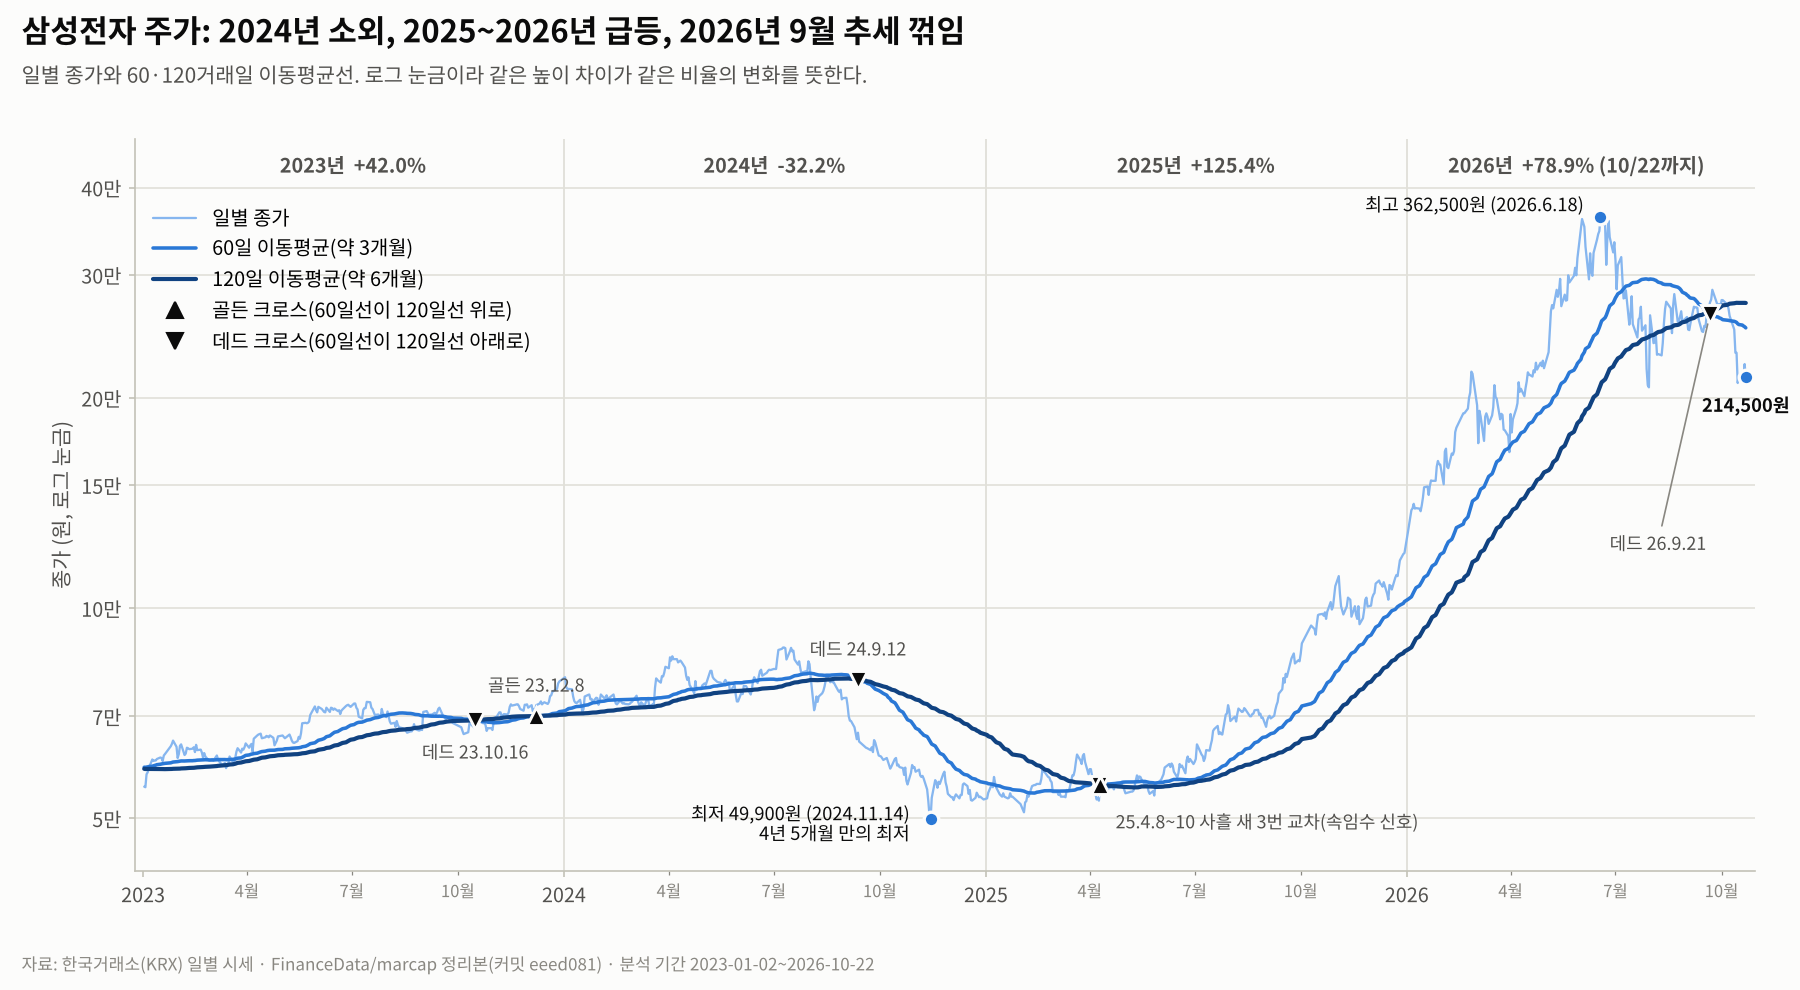

,date,type
0,2023-10-16,데드 크로스
1,2023-12-08,골든 크로스
2,2024-09-12,데드 크로스
3,2025-04-08,골든 크로스
4,2025-04-09,데드 크로스
5,2025-04-10,골든 크로스
6,2026-09-21,데드 크로스


In [11]:
display(Image(filename=P.fig_price_trend(daily, res)))
pd.DataFrame(res["crossovers"]).assign(date=lambda x: pd.to_datetime(x["date"]).dt.date)

**관찰:** 연도별 +42.0% → -32.2% → +125.4% → +78.9%(10/22까지). 60일선이 120일선 아래로 내려간 2024-09-12부터 다시 올라선 2025-04-10까지가 하락 국면이고, 2026-09-21에 다시 데드 크로스가 났다. 2025년 4월 8~10일에는 두 선이 0.1%도 차이 나지 않아 사흘 새 교차가 세 번 생겼다.

**해석(가설):** 2024년 하락 국면은 3분기 실적 부진과 HBM3E 품질 테스트 미통과 보도 시기와 겹친다. 이동평균 교차는 두 선이 붙어 있을 때 속임수 신호가 잦고, 이미 일어난 변화를 늦게 확인한다.

### Q2. 상대 성과: 같은 사이클, 다른 성과

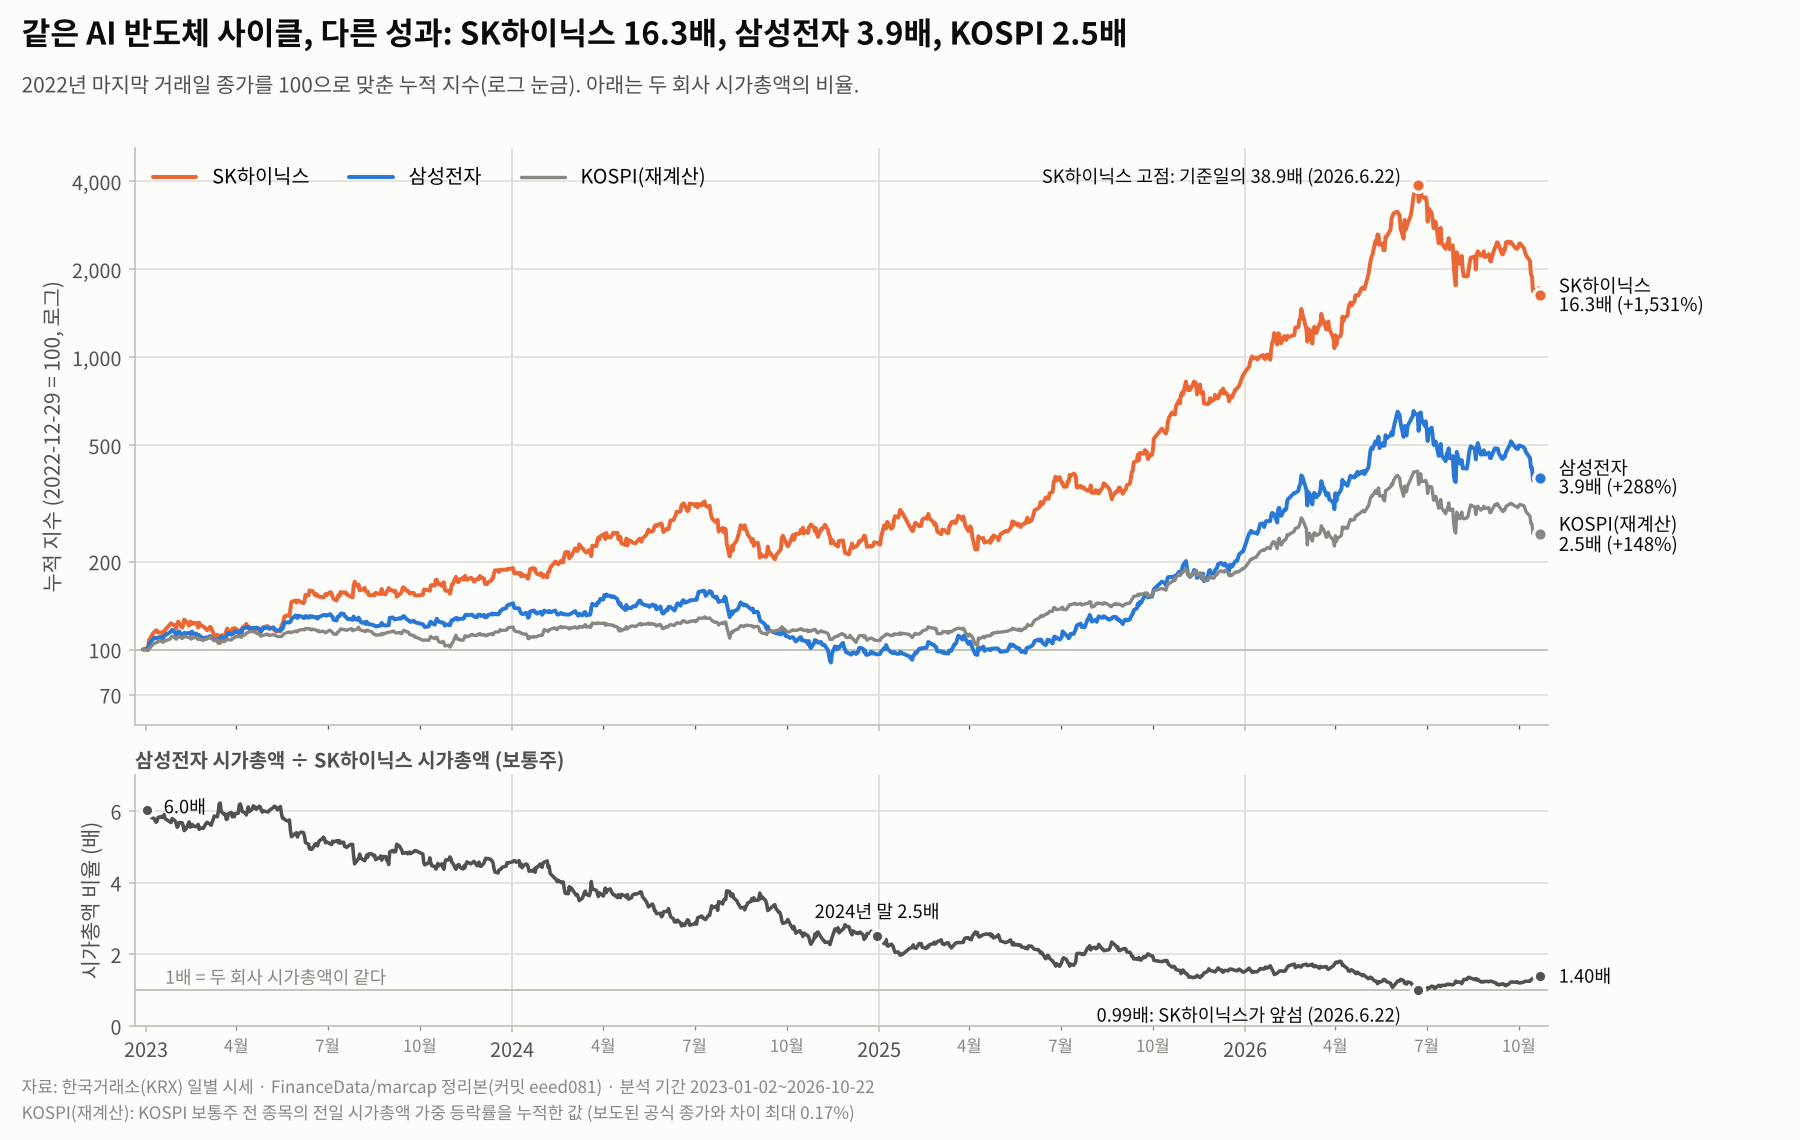

시가총액 비율(삼성전자 ÷ SK하이닉스): 6.01배 → 최저 0.99배(2026-06-22) → 1.40배
SK하이닉스가 더 컸던 날: 2 일, 2026-06-22 ~ 2026-06-23
상대 성과 = (1 + 삼성전자) ÷ (1 + SK하이닉스) − 1, 로그 격차 몫 = 4년 격차 중 그해 몫(%)


,sec_pct,skh_pct,diff_pctpt,relative_pct,log_gap_share_pct
2023,42.0,88.7,-46.7,-24.8,19.8
2024,-32.2,22.9,-55.1,-44.9,41.4
2025,125.4,274.4,-149.0,-39.8,35.3
2026YTD,78.9,87.9,-9.0,-4.8,3.4


In [12]:
display(Image(filename=P.fig_relative_performance(daily, res)))
cz = res["concentration"]
print(f"시가총액 비율(삼성전자 ÷ SK하이닉스): {cz['ratio_start']:.2f}배 → 최저 {cz['ratio_min']:.2f}배({cz['ratio_min_date'].date()}) → {cz['ratio_end']:.2f}배")
print("SK하이닉스가 더 컸던 날:", cz["skh_bigger_days"], "일,", cz["skh_bigger_first"].date(), "~", cz["skh_bigger_last"].date())
rel = pd.DataFrame(res["relative"]["by_year"]).T[["sec_pct", "skh_pct", "diff_pctpt", "relative_pct", "log_gap_share_pct"]]
print("상대 성과 = (1 + 삼성전자) ÷ (1 + SK하이닉스) − 1, 로그 격차 몫 = 4년 격차 중 그해 몫(%)")
rel.astype(float).round(1)

**관찰:** 2022년 말 대비 삼성전자 3.9배, SK하이닉스 16.3배, KOSPI 2.5배. 상대 성과로 보면 격차가 가장 크게 벌어진 해는 방향까지 반대였던 2024년(-44.9%, 4년 격차의 41%)이다. 2026년에는 6월 22일까지 다시 벌어졌다가(상대 성과 -34.2%) 그 뒤 하락장에서 크게 좁혀졌다(+44.8%).

**해석(가설):** AI 가속기용 HBM 공급 경쟁의 차이가 이익 기대 차이로 이어졌을 가능성. 주가만으로는 확인할 수 없어 분기 실적·HBM 매출 데이터로 검증이 필요하다.

### Q3. 변동성과 급변일

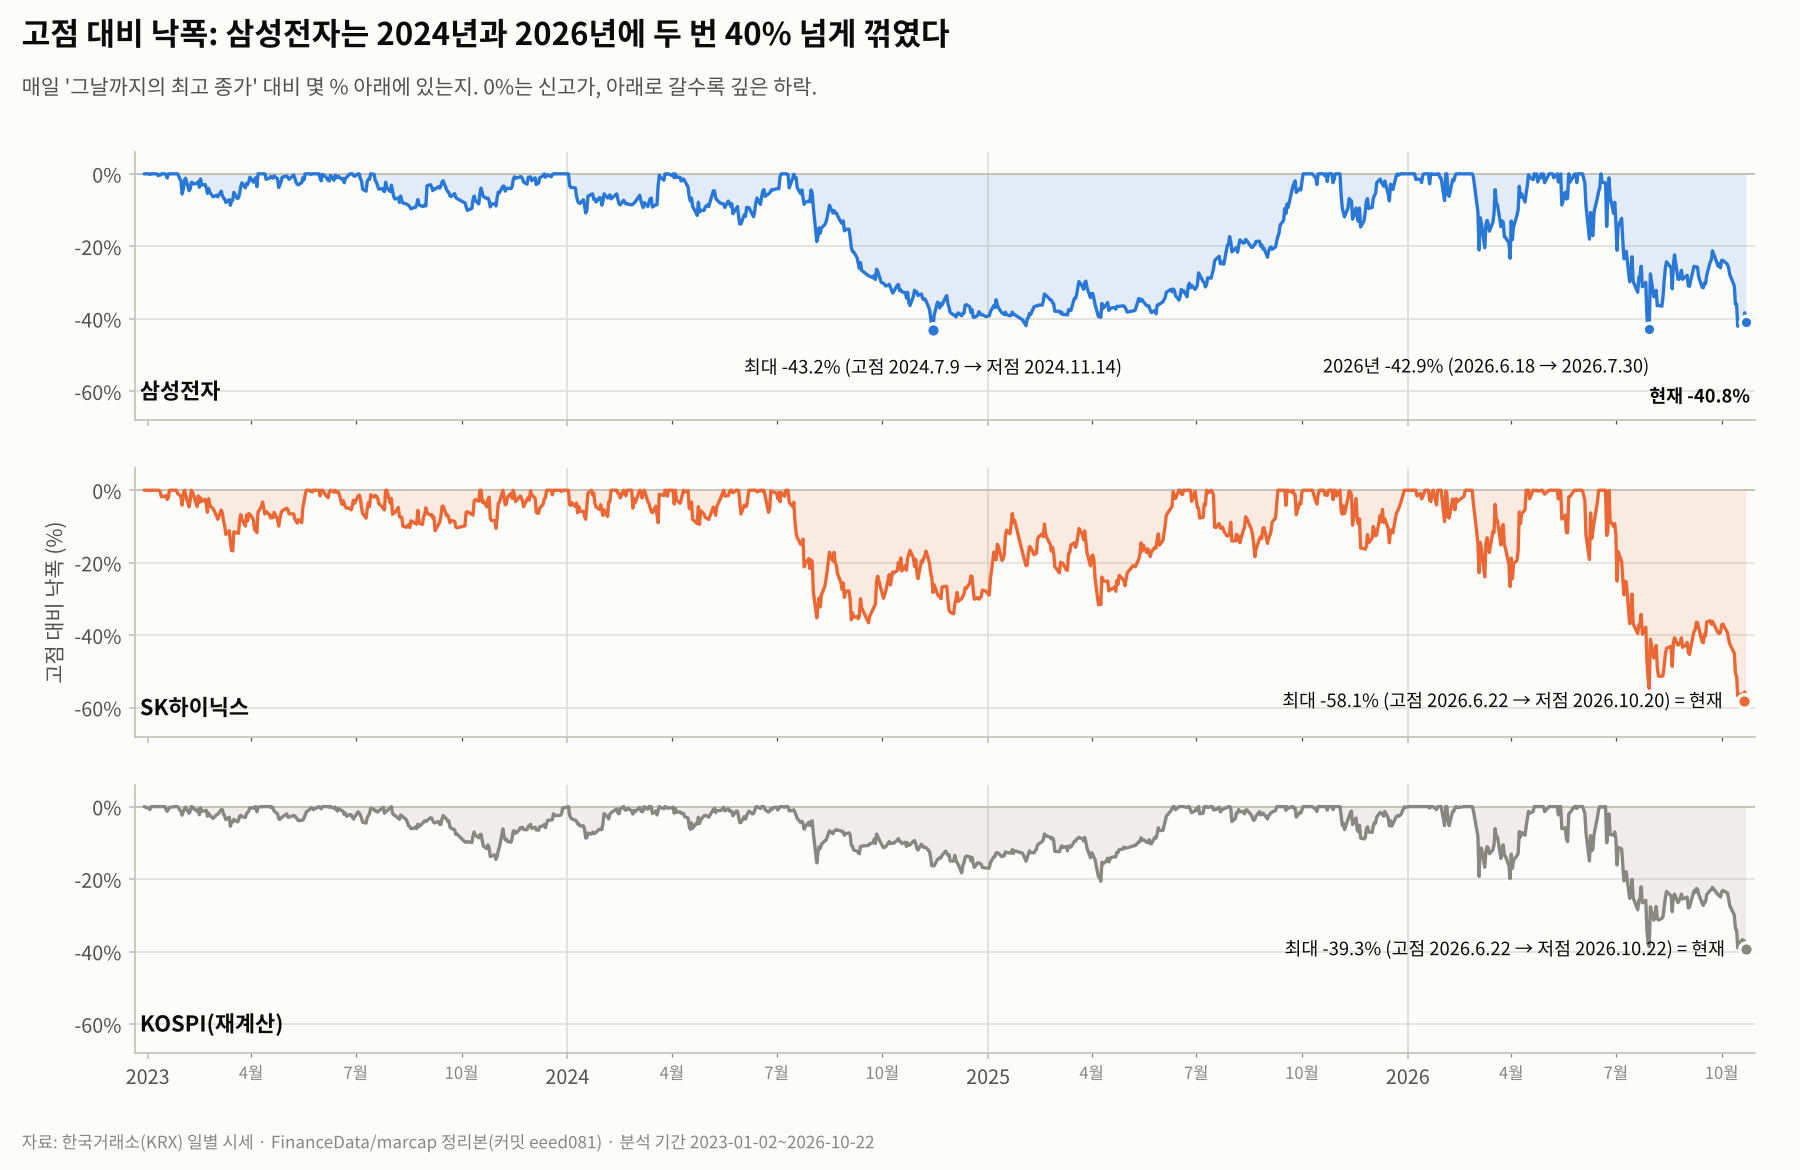

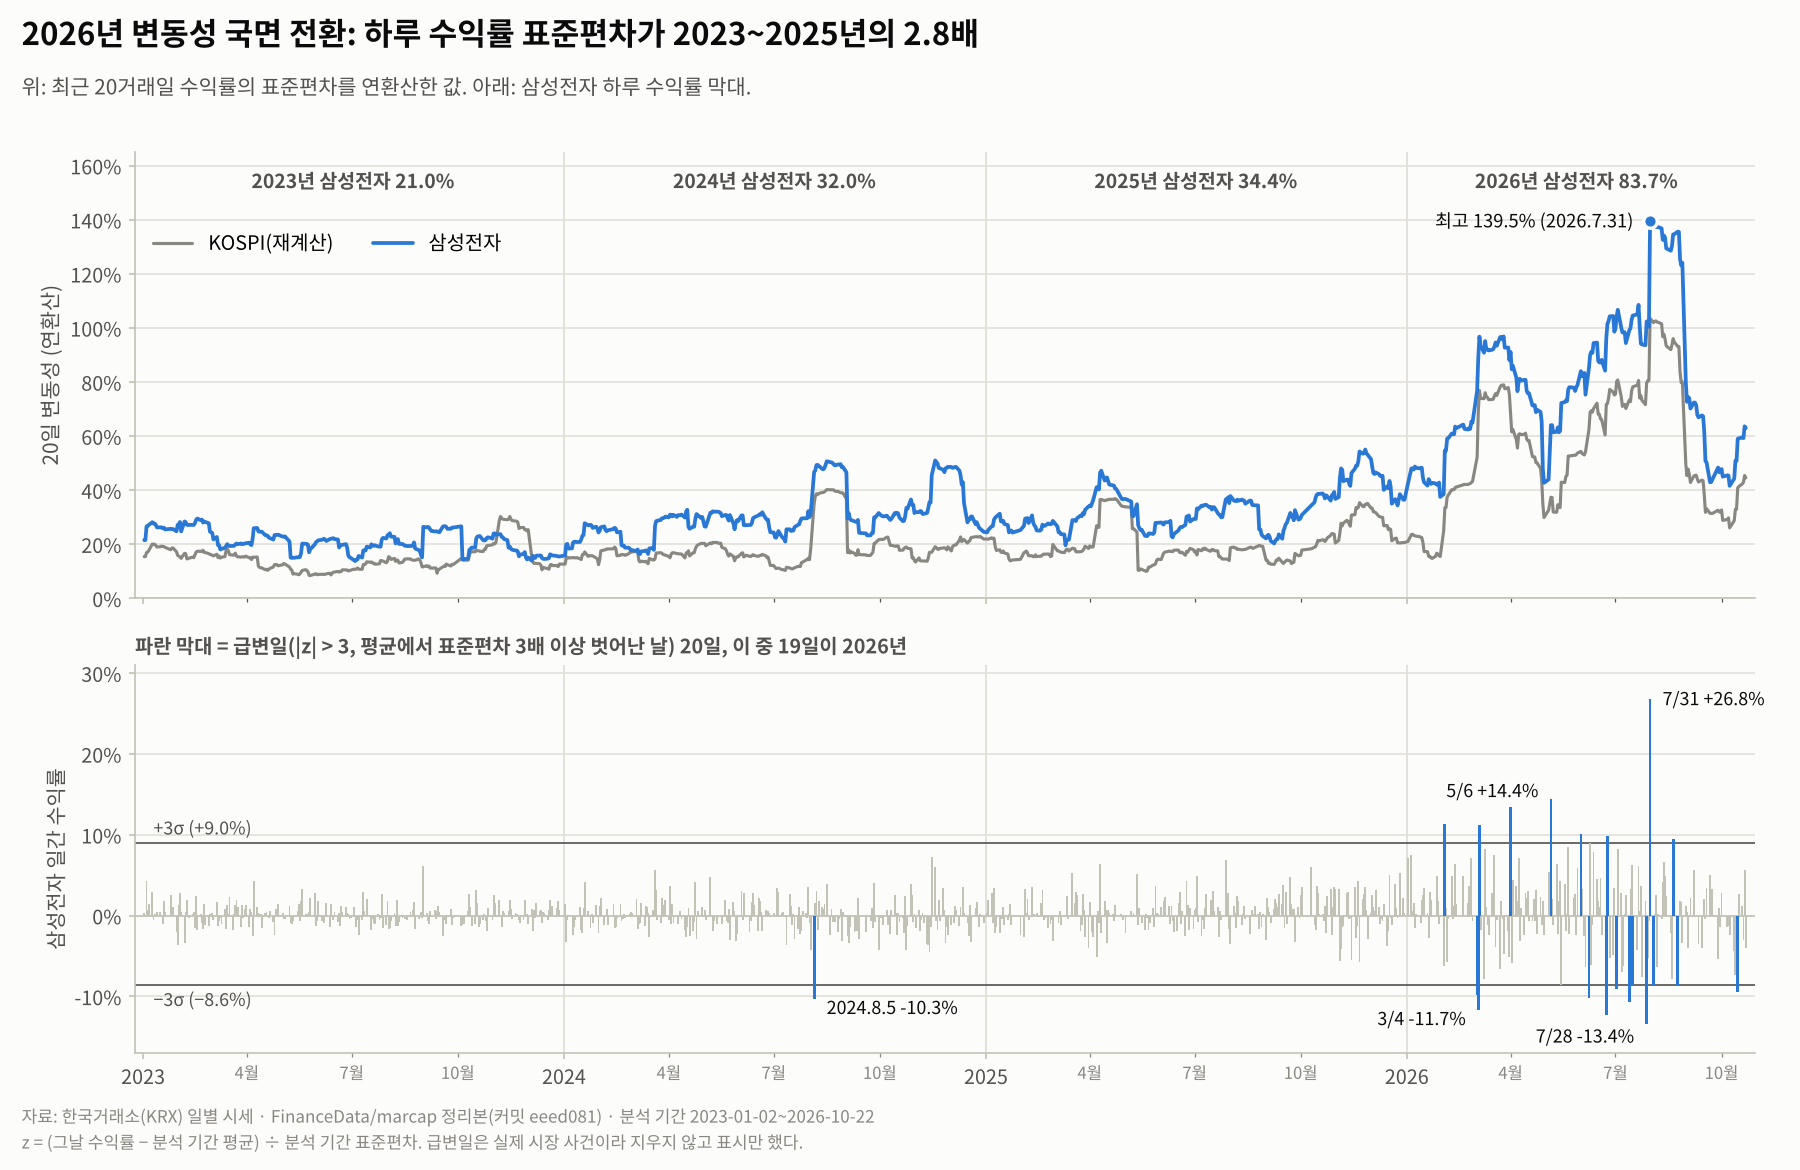

In [13]:
display(Image(filename=P.fig_drawdown(daily, res)))
display(Image(filename=P.fig_volatility(daily, res)))

In [14]:
a = prepare.analysis_slice(daily)
ext_days = M.extreme_days(a)
sec_ext = ext_days[ext_days["sec_extreme"]][["sec_ret", "sec_z", "skh_ret", "kospi_ret", "ex2_ret", "ex2_same_dir_2pct"]]
print("삼성전자 급변일과 같은 날 다른 시계열의 수익률(%)")
sec_ext.round(2)

삼성전자 급변일과 같은 날 다른 시계열의 수익률(%)


,sec_ret,sec_z,skh_ret,kospi_ret,ex2_ret,ex2_same_dir_2pct
Date,,,,,,
2024-08-05,-10.30,-3.57,-9.87,-8.76,-8.18,True
2026-02-03,11.37,3.80,9.28,6.83,4.61,True
2026-03-03,-9.88,-3.42,-11.50,-7.24,-5.00,True
2026-03-04,-11.74,-4.05,-9.58,-12.05,-12.78,True
2026-03-05,11.27,3.77,10.84,9.63,8.64,True
2026-04-01,13.40,4.49,10.66,8.43,5.93,True
2026-05-06,14.41,4.83,10.64,6.44,1.59,False
2026-06-01,10.09,3.37,1.29,3.68,1.22,False
2026-06-08,-10.18,-3.53,-7.68,-8.28,-7.39,True


**관찰:** 삼성전자 하루 수익률 표준편차는 2023~2025년 1.88%에서 2026년 5.27%로 커졌다. 급변일 20일 중 19일이 2026년이고, 19일은 두 종목을 뺀 나머지 시장도 같은 방향이었다.

**해석(가설):** 2026년의 급등락은 대부분 시장 전체 충격(중동 전쟁 우려, 레버리지 강제 매도, 미국 긴축 우려 보도)과 겹친다. 레버리지 데이터는 없어 직접 검증하지 못했다.

### Q4. 동조화와 쏠림

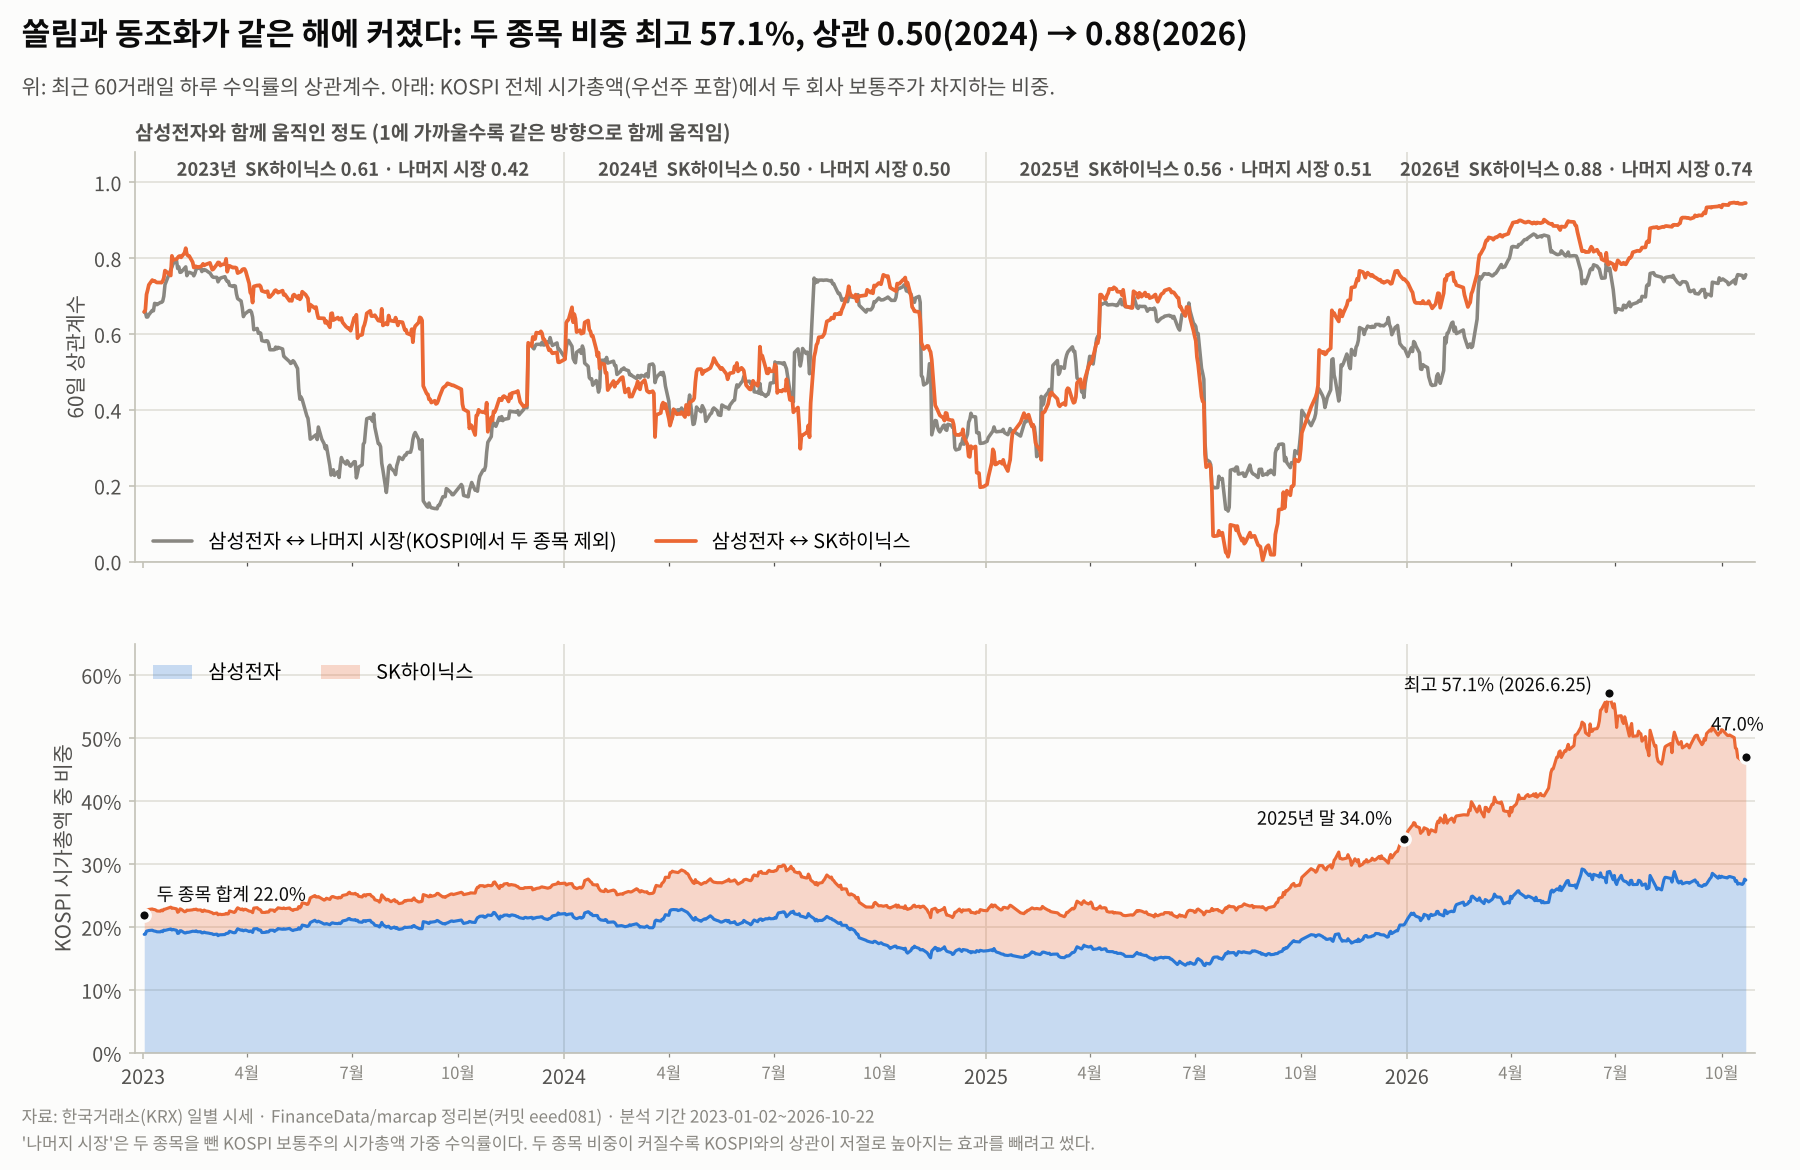

,year,corr_sec_skh,corr_sec_ex2,corr_sec_kospi,share_two_mean_pct
0,2023,0.606,0.420,0.673,24.270
1,2024,0.498,0.503,0.753,25.914
2,2025,0.561,0.507,0.743,24.792
3,2026,0.878,0.743,0.946,45.151
4,전체,0.741,0.648,0.882,29.254


In [15]:
display(Image(filename=P.fig_coupling(daily, res)))
pd.DataFrame(res["yearly_corr"]).round(3)

**관찰:** 삼성전자·SK하이닉스 상관 0.50(2024) → 0.88(2026). 두 회사의 KOSPI 비중은 22.0%에서 최고 57.1%까지 올랐다.

**해석(가설):** 두 종목 비중이 커진 시기와 상관이 높아진 시기가 2026년으로 겹친다. 지수 단위 매매와 잦은 시장 전체 충격이 상관을 끌어올렸다는 가설을 세웠다. 나머지 시장과의 상관도 올라 쏠림의 기계적 효과만으로는 설명되지 않는다. 변동성이 큰 시기에는 상관이 높게 측정되는 경향(Forbes & Rigobon, 2002)이 있어 일부는 측정 효과일 수 있다.

### Q5. 계절성: 달력 효과 확인

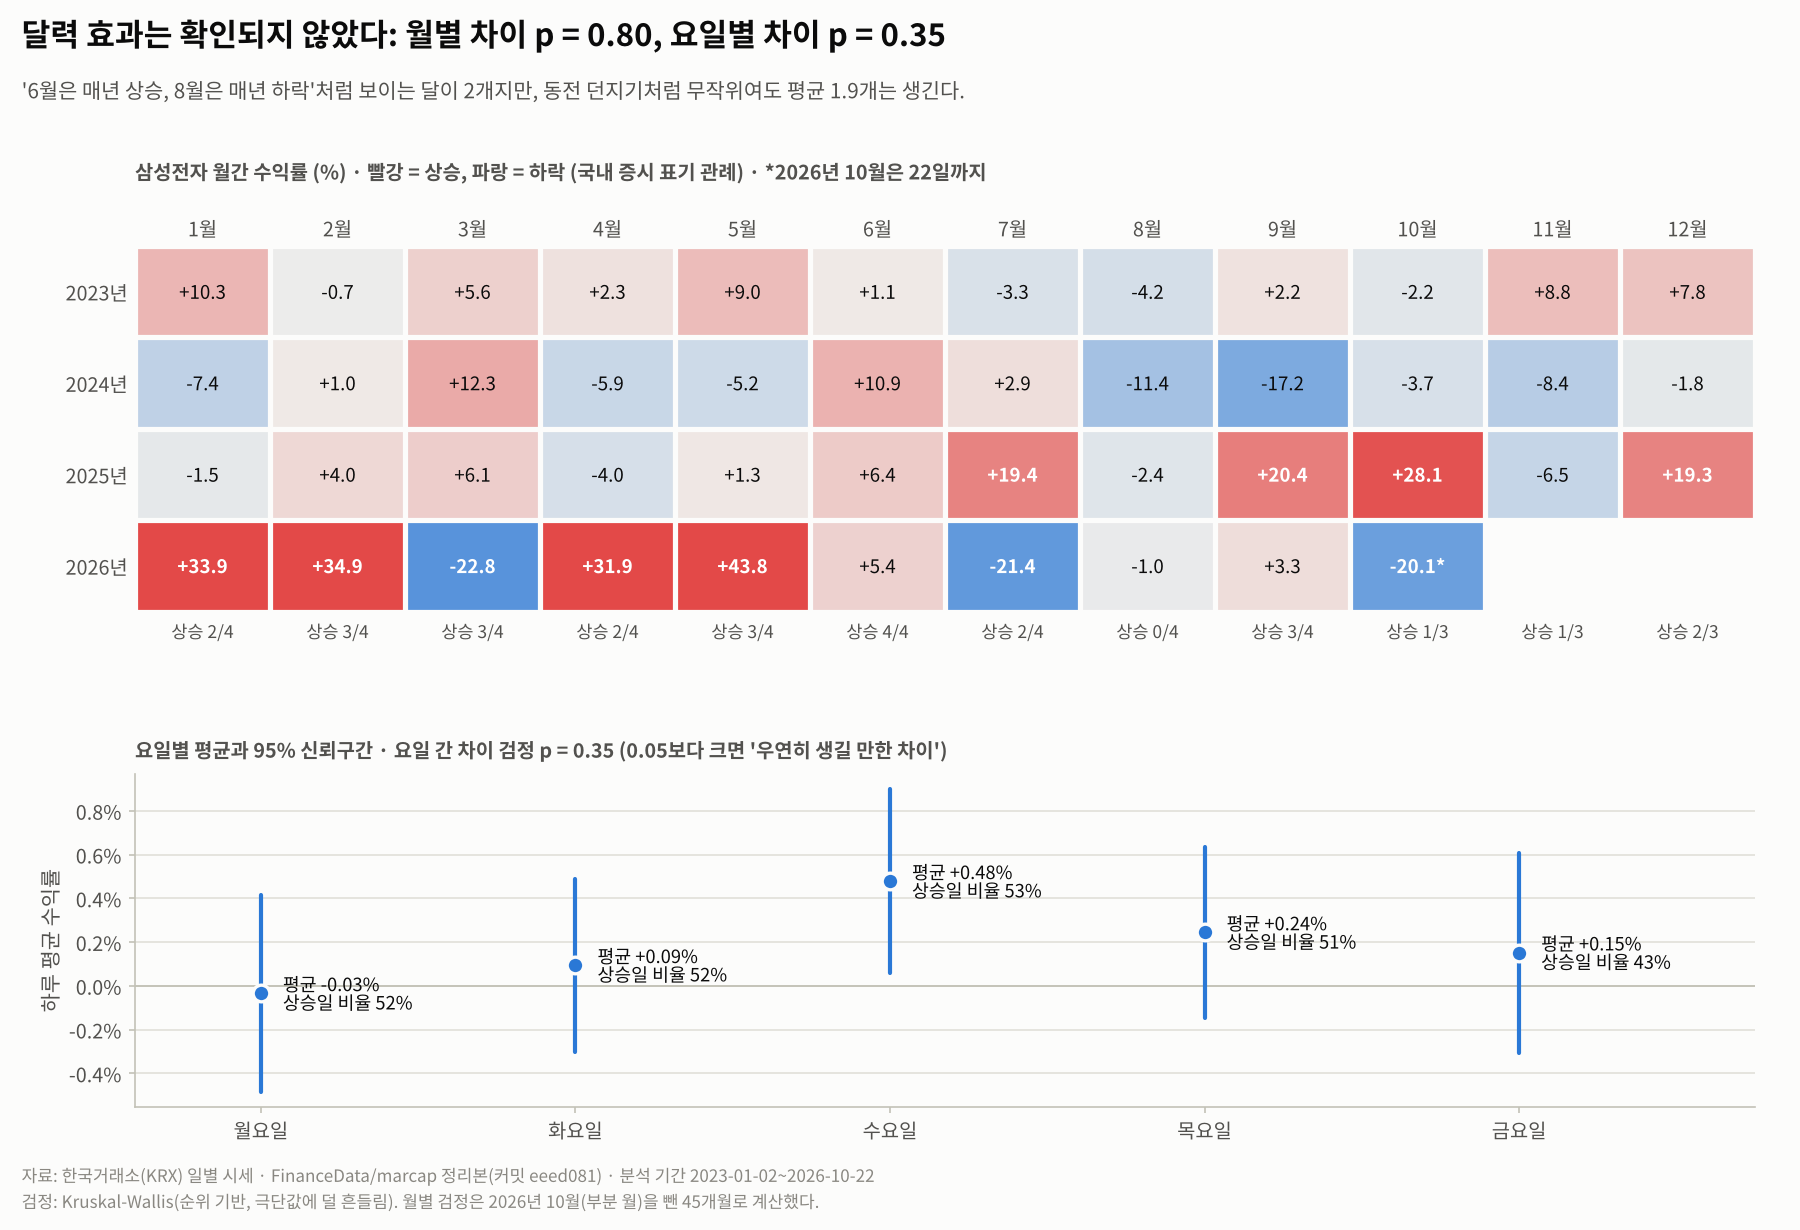

월별 차이 Kruskal-Wallis p = 0.8
요일별 차이 p (전체 / 2023~2025) = {'kruskal_p_all': 0.347, 'kruskal_p_2023_2025': 0.533}


,weekday,n,mean_pct,median_pct,win_rate_pct,ci95_low,ci95_high
0,월,180,-0.033,0.144,51.667,-0.484,0.417
1,화,186,0.095,0.137,51.613,-0.301,0.491
2,수,186,0.479,0.280,53.226,0.059,0.899
3,목,189,0.245,0.138,51.323,-0.147,0.637
4,금,186,0.152,-0.144,43.011,-0.305,0.610


In [16]:
display(Image(filename=P.fig_calendar(daily, res, extras["monthly"], extras["weekday"])))
print("월별 차이 Kruskal-Wallis p =", round(res["month_of_year_test_p"], 3))
print("요일별 차이 p (전체 / 2023~2025) =", {k: round(v, 3) for k, v in res["weekday_test"].items()})
extras["weekday"].round(3)

**관찰:** 6월(4년 모두 상승)과 8월(4년 모두 하락)처럼 보이는 달이 2개지만, 무작위여도 평균 1.9개가 생긴다. 월별 p = 0.80, 요일별 p = 0.35.

**해석:** 4년 표본으로는 달력 효과를 주장할 근거가 없다.

## 5. 보너스

### 5.1 STL 분해

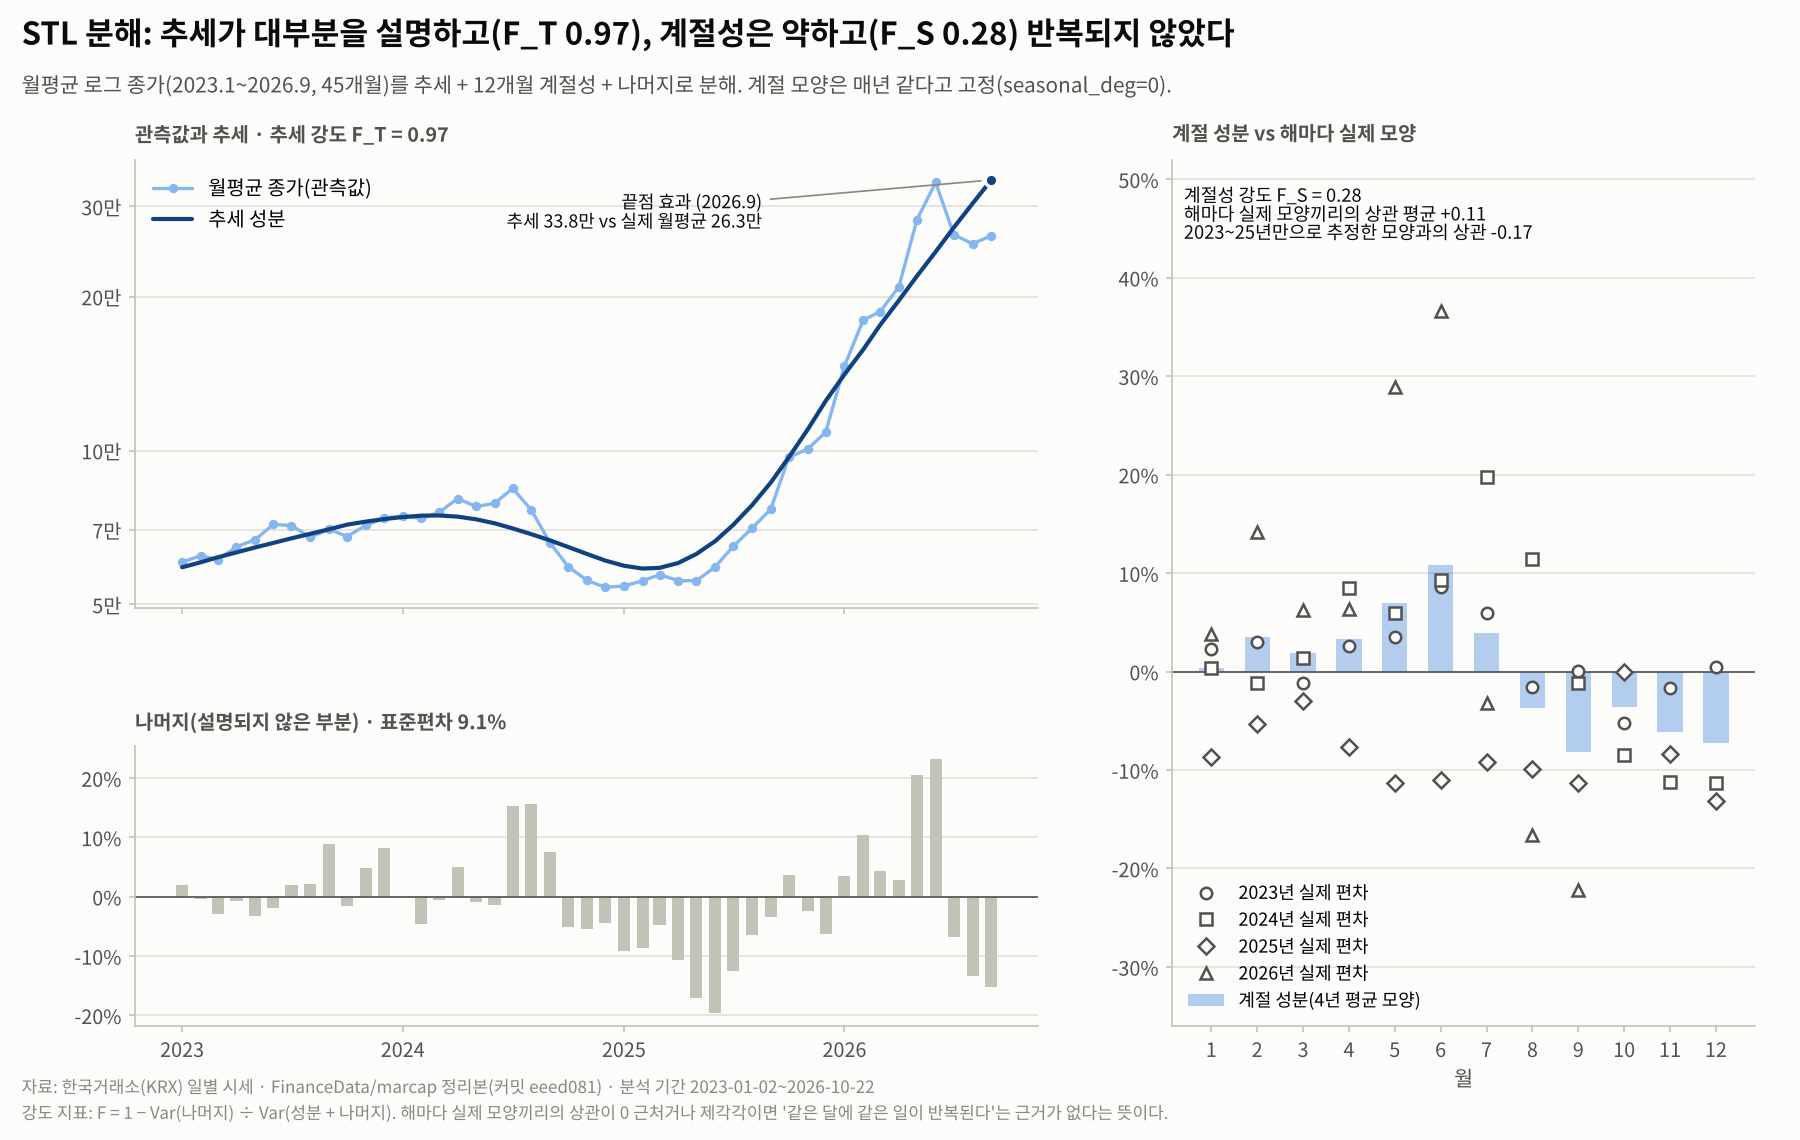

{'n_months': 45,
 'period': 12,
 'seasonal_window': 999,
 'seasonal_deg': 0,
 'robust': False,
 'trend_strength': 0.969,
 'seasonal_strength': 0.282,
 'robust_trend_strength': 0.953,
 'robust_seasonal_strength': 0.146,
 'seasonal_peak_month': 6,
 'seasonal_trough_month': 9,
 'trend_change_pct': 471.861,
 'observed_change_pct': 334.926,
 'last_month': Timestamp('2026-09-01 00:00:00'),
 'trend_last_won': 338066.619,
 'observed_last_won': 263095.914,
 'trend_end_gap_pct': 28.496,
 'resid_std_pct': 9.099,
 'year_pair_corr_mean': 0.114,
 'seasonal_2023_2025_vs_full_corr': -0.17}

In [17]:
parts, stl_info = A.stl_decompose(daily)
display(Image(filename=P.fig_stl(parts, stl_info)))
{k: (round(v, 3) if isinstance(v, float) else v) for k, v in stl_info.items() if k not in ("seasonal_effect_by_month_pct", "year_pair_corr")}

**관찰:** 계절 모양을 매년 같다고 고정(seasonal=999, seasonal_deg=0)하고 분해했다. 추세 강도 0.97, 계절성 강도 0.28(robust 분해 0.15). 추세를 뺀 월별 값의 연도 간 상관 평균 +0.11, 2023~2025년만으로 추정한 모양과의 상관 -0.17. 마지막 달 추세 338,067원은 실제 월평균 263,096원보다 28.5% 높다(끝점 효과).

**해석(가설):** 계절성은 약하고, 계절 모양(6월 상승·9월 하락)은 2026년 급등락의 영향이 커서 해마다 반복되는 패턴이라는 근거가 없다.

### 5.2 베이스라인 예측과 백테스트

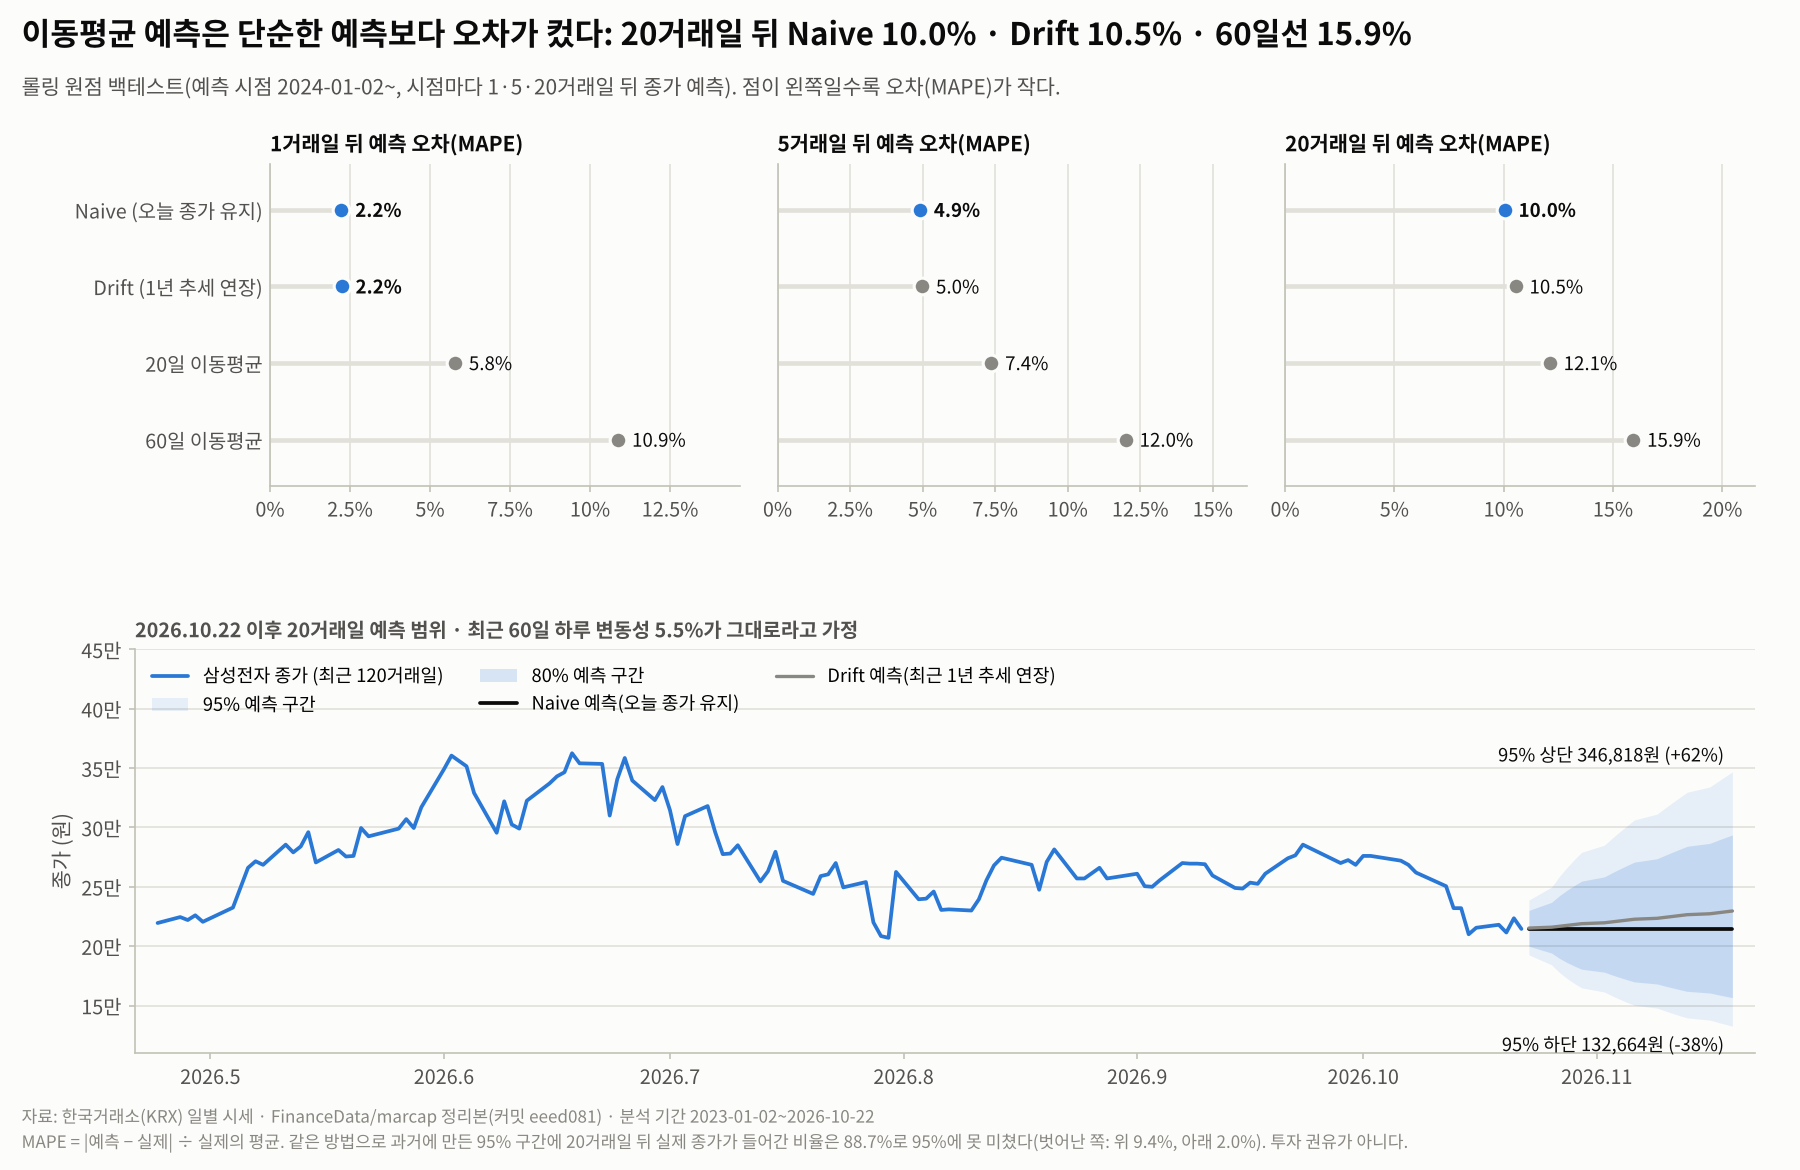

h,1,5,20
method,,,
drift,2.24,4.98,10.54
ma20,5.78,7.36,12.10
ma60,10.88,12.00,15.92
naive,2.23,4.91,10.04


In [18]:
bt = A.backtest(daily)
bt_sum = A.backtest_summary(bt)
fan, fan_info = A.future_fan(daily)
coverage = A.fan_coverage(daily)
display(Image(filename=P.fig_forecast(daily, bt_sum, fan, fan_info, coverage)))
bt_sum.pivot(index="method", columns="h", values="mape_pct").round(2)

In [19]:
print("예측 구간 적중률(%): 같은 방법으로 과거 매 거래일 만든 구간에 실제 종가가 들어간 비율")
coverage.round(1)

예측 구간 적중률(%): 같은 방법으로 과거 매 거래일 만든 구간에 실제 종가가 들어간 비율


,h,level,coverage_pct,above_pct,below_pct,n,coverage_2024_pct,coverage_2025_pct,coverage_2026_pct
0,1,80,78.6,12.3,9.1,681,79.9,77.3,78.5
1,1,95,93.0,4.1,2.9,681,93.0,94.2,91.3
2,5,80,78.1,13.1,8.7,677,76.6,76.4,82.2
3,5,95,92.6,4.6,2.8,677,93.4,88.8,96.3
4,20,80,74.9,18.7,6.3,662,77.9,71.5,75.6
5,20,95,88.7,9.4,2.0,662,91.0,81.8,94.9


**관찰:** Naive(오늘 종가 유지)와 Drift(최근 1년 추세 연장)의 오차는 비슷했고, 20·60일 이동평균은 1·5·20거래일 모두 오차가 더 컸다. 2026-10-22 이후 20거래일의 95% 예측 구간은 132,664원 ~ 346,818원이다. 같은 방법의 과거 95% 구간에 20거래일 뒤 실제 종가가 들어간 비율은 88.7%로 95%에 못 미쳤다.

**해석(가설):** 이 국면에서는 점 예측이 거의 의미가 없고, 구간도 이름값(95%)보다 자주 빗나간다. 가정(랜덤워크, 변동성 일정, 정규분포 근사)과 한계는 리포트 8.3절에 정리했다.

## 6. 정리

- 이 기간 삼성전자 주가는 '계절'보다 '국면'으로 더 잘 설명됐다: 2024년 시장보다 깊은 하락(회사 고유 요인이라는 가설), 2025년부터 2026년 6월까지 반도체 랠리, 2026년 시장 전체 급등락.
- 인사이트·결론·한계점·AI 사용 로그는 [REPORT.md](REPORT.md), 기간을 바꿔 보는 탐색은 [웹 대시보드](https://sungtae10.github.io/codyssey-semiconductor-trend-analysis-M1-1/)에서 확인한다.